# 04 · Segurança: onde e como acontecem os acidentes da MRS

**Para quem:** a área de segurança operacional e de relação com as comunidades de uma ferrovia que atravessa cidades.

**Como:** usa os acidentes que as concessionárias declaram à ANTT (RAAF, 2004 a jan/2026), com o ponto do pátio da estação anterior ao acidente, e divide pela carga do SIADE (TKU) dos mesmos meses. Tudo vem dos marts `fct_acidentes` e `fct_acidentes_ferrovia_anual`.

**O que o dado aberto não permite:** o índice oficial da ANTT divide por trem·km, que não é publicado, e o arquivo do índice "de 2006 a 2025" saiu vazio; o oficial vai até 2019. A métrica daqui (acidentes graves por bilhão de TKU) favorece ferrovias de carga pesada e distância longa, então serve para acompanhar uma ferrovia ao longo do tempo melhor do que para ranquear ferrovias diferentes.

> Este notebook trata de mortes, e parte delas é registrada como suicídio. Se você está passando por um momento difícil, o CVV atende de graça, 24 horas, pelo **188** ou em cvv.org.br.

In [1]:
import sys; sys.path.insert(0, ".")
from comum import *
acid = sql("select * from marts.fct_acidentes")
anual = sql("select * from marts.fct_acidentes_ferrovia_anual")
mrs = acid[(acid.ferrovia == "MRS") & acid.ano.between(2011, 2025)]

## Pergunta 1. Dá para comparar um ano com outro?

In [2]:
completude = acid[acid.ano <= 2025].groupby("ano").agg(
    acidentes=("acidente_id", "size"),
    pct_graves=("grave", lambda s: round(100 * s.mean())),
    obitos=("obitos", "sum"),
    atropelamentos=("natureza", lambda s: (s == "Atropelamento").sum()),
    causa_nao_informada=("causa_direta", lambda s: (s == "Não informada").sum()),
)
completude.loc[2004:2013]

,acidentes,pct_graves,obitos,atropelamentos,causa_nao_informada
ano,,,,,
2004,272,100,0,127,104
2005,261,100,0,142,80
2006,353,100,0,189,82
2007,317,100,0,176,65
2008,271,100,0,136,128
2009,323,100,1,172,16
2010,545,63,33,178,46
2011,1028,33,117,196,0
2012,959,39,96,211,0


**Resposta:** só a partir de 2011.
- **De 2004 a 2009, 100% dos registros são graves e o país inteiro soma 1 óbito em seis anos**, mesmo com 127 a 189 atropelamentos por ano. Não é que ninguém morria: o campo não era preenchido, e os acidentes não graves não entravam no arquivo.
- **2010 é a transição:** 545 registros, 63% graves, 33 óbitos. Em 2011 são 1.028 registros, 33% graves e 117 óbitos.
- Por isso o mart marca `registro_completo` e o painel abre em 2011–2025. Quem olhar a contagem bruta desde 2004 vai ver os acidentes "triplicarem" em 2011 — o que mudou foi o registro, não a ferrovia.

## Pergunta 2. Como a MRS se compara com as outras ferrovias?

In [3]:
periodo = anual[anual.ano.between(2011, 2025)].groupby("ferrovia")[["acidentes", "graves", "obitos", "tku"]].sum()
periodo = periodo[periodo.tku >= 15e9]  # ao menos 1 bilhão de TKU por ano
periodo["graves_por_bi_tku"] = (1e9 * periodo.graves / periodo.tku).round(2)
periodo["obitos_por_bi_tku"] = (1e9 * periodo.obitos / periodo.tku).round(2)
periodo["tku_bi"] = (periodo.tku / 1e9).round(0)
periodo.drop(columns="tku").sort_values("graves_por_bi_tku")

,acidentes,graves,obitos,graves_por_bi_tku,obitos_por_bi_tku,tku_bi
ferrovia,,,,,,
EFC,341,125,72,0.06,0.03,2165.0
RMN,218,72,13,0.14,0.03,498.0
RMC,13,5,2,0.15,0.06,34.0
EFVM,415,180,101,0.19,0.11,930.0
FNSTN,75,35,10,0.30,0.09,117.0
MRS,1770,844,531,0.91,0.57,930.0
FCA,2489,772,208,2.50,0.67,308.0
RMS,3262,1163,317,5.46,1.49,213.0
RMP,1583,663,260,6.60,2.59,100.0


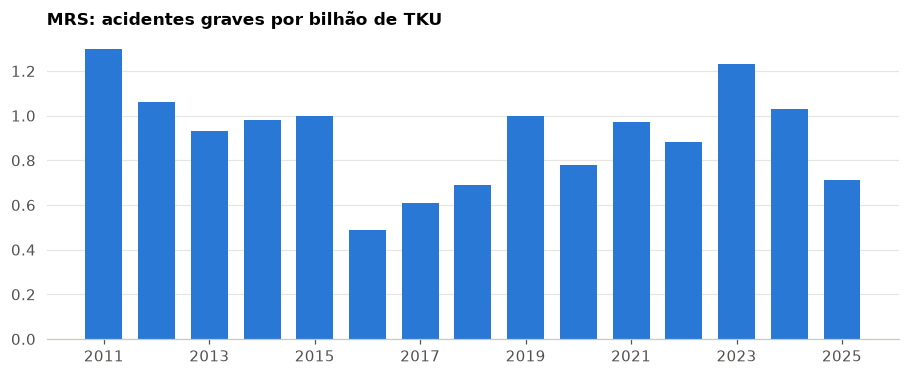

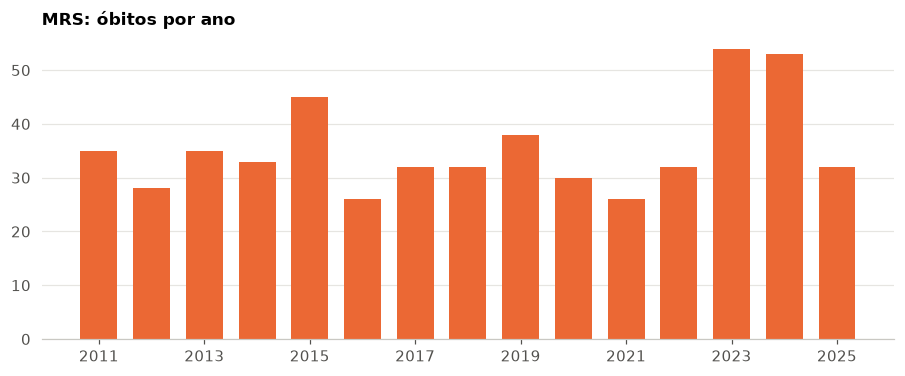

ano,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
acidentes,132.000000,143.00000,115.000000,112.000000,122.000000,95.000000,107.000000,107.000000,101.00,104.00,119.00,104.00,156.00,137.00,116.00
graves,80.000000,66.00000,57.000000,63.000000,65.000000,32.000000,39.000000,44.000000,48.00,41.00,55.00,51.00,82.00,70.00,51.00
obitos,35.000000,28.00000,35.000000,33.000000,45.000000,26.000000,32.000000,32.000000,38.00,30.00,26.00,32.00,54.00,53.00,32.00
graves_por_bilhao_tku,1.300000,1.06000,0.930000,0.980000,1.000000,0.490000,0.610000,0.690000,1.00,0.78,0.97,0.88,1.23,1.03,0.71
indice_oficial,8.203943,9.19324,6.927433,7.143874,8.186283,6.354281,7.210491,7.394069,8.36,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
serie = anual[(anual.ferrovia == "MRS") & anual.ano.between(2011, 2025)].set_index("ano")
fig, ax = plt.subplots()
ax.bar(serie.index, serie.graves_por_bilhao_tku, color=AZUL, width=0.7)
ax.set_xticks(range(2011, 2026, 2))
ax.set(title="MRS: acidentes graves por bilhão de TKU")
plt.show()
fig, ax = plt.subplots()
ax.bar(serie.index, serie.obitos, color=LARANJA, width=0.7)
ax.set_xticks(range(2011, 2026, 2))
ax.set(title="MRS: óbitos por ano")
plt.show()
serie[["acidentes", "graves", "obitos", "graves_por_bilhao_tku", "indice_oficial"]].T

**Resposta:** pela carga, a MRS fica no meio; em mortes, é a primeira.
- **Graves por bilhão de TKU, 2011–2025:** 0,91 na MRS, contra 0,06 na EFC, 0,19 na EFVM, 2,50 na FCA e 6,60 na RMP. A métrica favorece quem leva minério pesado por distância longa (a EFC tem 2.165 bi TKU no período; a MRS, 930), então a comparação justa é com a EFVM, que tem o mesmo TKU: a MRS registra **4,7 vezes mais acidentes graves** que ela (844 contra 180).
- **Óbitos absolutos, 2011–2025: 531 na MRS, o maior número entre as concessionárias** (RMS 317, RMP 260, FCA 208, EFVM 101).
- **Ao longo do tempo:** a taxa caiu de 1,30 (2011) para 0,49 (2016), voltou a 1,23 em 2023 e fechou 2025 em 0,71. Os óbitos foram de 26 (2016) a 54 (2023), e 53 em 2024.
- **O índice oficial**, até 2019, oscila entre 6,4 e 9,2 por milhão de trem·km, sem tendência. Depois de 2019 não há número oficial aberto.

## Pergunta 3. Que tipo de acidente mata na MRS?

In [5]:
nat = mrs.groupby("natureza").agg(acidentes=("acidente_id", "size"), obitos=("obitos", "sum"),
                                 em_passagem_em_nivel=("em_passagem_em_nivel", "sum"))
nat["pct_acidentes"] = (100 * nat.acidentes / nat.acidentes.sum()).round(1)
nat["pct_obitos"] = (100 * nat.obitos / nat.obitos.sum()).round(1)
nat.sort_values("acidentes", ascending=False)

,acidentes,obitos,em_passagem_em_nivel,pct_acidentes,pct_obitos
natureza,,,,,
Atropelamento,1051,490,304,59.4,92.3
Abalroamento,597,41,536,33.7,7.7
Descarrilamento,111,0,4,6.3,0.0
Colisão,11,0,0,0.6,0.0


**Resposta:** atropelamento. A operação quase não mata; o que mata é a convivência com a cidade.
- **Atropelamentos são 59% dos acidentes e 92% dos óbitos** (490 de 531, 2011–2025).
- **Abalroamentos** (o trem atinge um veículo) são 34% dos acidentes, 90% deles em passagem em nível, e respondem por 41 óbitos.
- **Descarrilamentos foram 111 em 15 anos, sem nenhum óbito.** É o tipo de acidente que depende só da ferrovia (via, vagão, operação), e ele é raro e não fatal na MRS.
- Ou seja: o problema de segurança da MRS não está no trilho, está na faixa de domínio dentro das cidades.

## Pergunta 4. Onde?

In [6]:
mun = mrs.groupby(["municipio", "uf"]).agg(acidentes=("acidente_id", "size"), obitos=("obitos", "sum"),
    atropelamentos=("natureza", lambda s: (s == "Atropelamento").sum())).sort_values("acidentes", ascending=False)
mun["pct_obitos_mrs"] = (100 * mun.obitos / mrs.obitos.sum()).round(1)
mun.head(10)

,,acidentes,obitos,atropelamentos,pct_obitos_mrs
municipio,uf,,,,
Juiz de Fora,MG,221,104,187,19.6
Barra Mansa,RJ,83,12,41,2.3
Itaguai,RJ,81,12,35,2.3
Nova Iguacu,RJ,62,16,20,3.0
Santos Dumont,MG,60,14,31,2.6
Tres Rios,RJ,60,22,36,4.1
Paraiba do Sul,RJ,55,10,26,1.9
Barra do Pirai,RJ,52,9,31,1.7
Brumadinho,MG,50,9,15,1.7


In [7]:
jf = mrs[mrs.municipio == "Juiz de Fora"]
jf.groupby(["estacao_anterior", "estacao_posterior"], dropna=False).agg(
    acidentes=("acidente_id", "size"), obitos=("obitos", "sum")).sort_values("acidentes", ascending=False).head(8)

,,acidentes,obitos
estacao_anterior,estacao_posterior,,
Posto km 271,Juiz de Fora,39,27
Juiz de Fora,Mariano Procópio,30,15
Francisco Bernardino,Benfica,29,18
Mariano Procópio,Francisco Bernardino,28,14
Francisco Bernardino,NaN,21,5
Juiz de Fora,NaN,20,4
Posto km 261,Retiro,14,5
Benfica,NaN,13,5


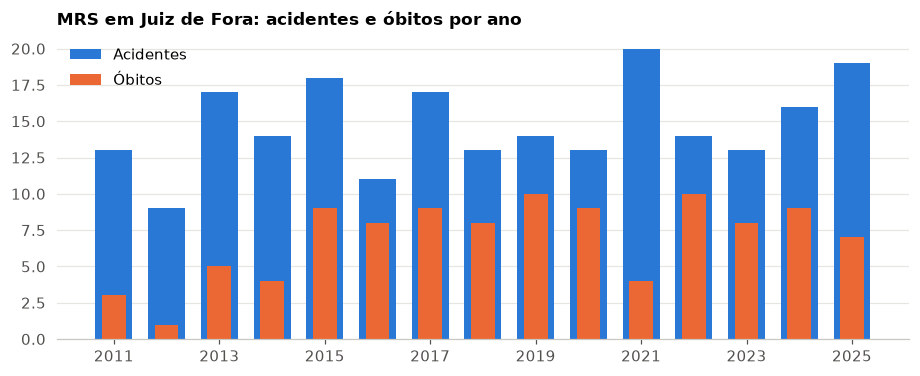

In [8]:
por_ano = jf.groupby("ano").agg(acidentes=("acidente_id", "size"), obitos=("obitos", "sum"))
fig, ax = plt.subplots()
ax.bar(por_ano.index, por_ano.acidentes, color=AZUL, width=0.7, label="Acidentes")
ax.bar(por_ano.index, por_ano.obitos, color=LARANJA, width=0.45, label="Óbitos")
ax.set_xticks(range(2011, 2026, 2)); ax.legend(loc="upper left")
ax.set(title="MRS em Juiz de Fora: acidentes e óbitos por ano")
plt.show()

**Resposta:** em Juiz de Fora, e num trecho de poucos quilômetros.
- **Juiz de Fora tem 221 acidentes e 104 óbitos de 2011 a 2025: 19,6% das mortes da MRS inteira**, num município. O segundo, Três Rios, tem 22 óbitos. 187 dos 221 acidentes em JF são atropelamentos.
- **O trecho urbano que vai do Posto km 271, ao sul do centro, até Benfica, ao norte** (Posto km 271 → Juiz de Fora → Mariano Procópio → Francisco Bernardino → Benfica) soma **126 acidentes e 74 dos 104 óbitos (71%)**.
- Não há tendência de queda: JF teve de 9 a 20 acidentes e de 1 a 10 óbitos por ano, com 19 acidentes e 7 óbitos em 2025.
- **Limite do dado:** o ponto é a estação anterior, não o quilômetro exato. O quilômetro está no mart (`km_inicial`), mas sem a geometria da linha não dá para pôr no mapa.

## Pergunta 5. O que o registro diz sobre a causa?

In [9]:
recente = acid[(acid.ferrovia == "MRS") & (acid.taxonomia_causa == "desde dez/2020") & (acid.data_ocorrencia <= pd.Timestamp("2025-12-31").date())]
fatais = recente[(recente.natureza == "Atropelamento") & (recente.obitos > 0)]
contrib = fatais.causa_contributiva.fillna("(vazia)").str.split(", ").explode().value_counts()
print(f"Atropelamentos com morte na MRS, dez/2020 a dez/2025: {len(fatais)}")
print(f"Com suicídio ou tentativa entre as causas: {fatais.causa_contributiva.str.contains('Suic', na=False).sum()}")
contrib.to_frame("menções")

Atropelamentos com morte na MRS, dez/2020 a dez/2025: 185
Com suicídio ou tentativa entre as causas: 84


,menções
causa_contributiva,
Suicídio ou tentativa de suicídio,84
Invasão da faixa de segurança (por terceiros),60
Falta de atenção à circulação (por terceiros),34
(vazia),16
Desobediência de sinal (por terceiros),11


**Resposta:** na MRS, quase metade dos atropelamentos com morte é registrada como suicídio ou tentativa.
- De dez/2020 a dez/2025 (quando a causa contributiva passou a existir), foram **185 atropelamentos com morte; 84 (45%) têm suicídio ou tentativa entre as causas**. Em Juiz de Fora, de 2021 a 2025, são 22 de 38.
- Logo depois vêm **invasão da faixa de segurança** (60 menções) e **falta de atenção à circulação** (34).
- Para a ferrovia, isso muda o tipo de resposta: muro e passarela atendem a invasão da faixa, mas o suicídio pede também parceria com a rede de saúde mental do município.
- A causa é o que a concessionária declara à ANTT, não conclusão de perícia.

## Pergunta 6. O que o dado aberto esconde

In [10]:
arquivos = sql("select arquivo, periodo_inicio, periodo_fim, formato_data, datas_ambiguas, linhas from raw.acidentes_arquivos order by periodo_inicio")
indice = sql("select arquivo, ano_final, linhas from raw.indice_acidentes_arquivos order by ano_final")
dup = sql("select count(*) as registros, count(distinct acidente_id) from staging.stg_antt__acidentes").iloc[0, 0] - len(acid)
print(f"Registros repetidos removidos: {dup}")
display(arquivos, indice)

Registros repetidos removidos: 30


,arquivo,periodo_inicio,periodo_fim,formato_data,datas_ambiguas,linhas
0,acidentes_ferroviarios_2004-2020.csv,2004-01-01,2020-11-30,DD/MM,3930,10824
1,acidentes_ferroviarios_12.2020-01.2026.csv,2020-12-01,2026-01-31,misto,1345,3710


,arquivo,ano_final,linhas
0,raaf_2019.csv,2019,182
1,raaf_2025.csv,2025,0


In [11]:
# A causa direta mudou de classificação com o arquivo de dezembro de 2020.
causas = acid[acid.ano <= 2025].groupby("taxonomia_causa").causa_direta.value_counts(normalize=True).mul(100).round(1).unstack(0)
causas.loc[["Interferência de Terceiro", "Casos Fortuitos ou de Força Maior", "Via Permanente", "Material Rodante", "Falha Humana"]]

taxonomia_causa,até nov/2020,desde dez/2020
causa_direta,,
Interferência de Terceiro,21.2,74.2
Casos Fortuitos ou de Força Maior,29.8,2.7
Via Permanente,24.5,15.2
Material Rodante,6.9,4.7
Falha Humana,4.8,1.9


**O que só apareceu ao montar o pipeline:**
- **Datas em dois formatos no mesmo arquivo.** No arquivo de dez/2020 em diante, toda data com dia até 12 veio como MM/DD (1º de dezembro de 2020 está como "12/01/2020") e as demais como DD/MM. São 1.345 linhas, 36% do arquivo. A ingestão decide o formato pela ordem do arquivo e para se a decisão não for unânime; hoje ela é: 1.345 a 0 no arquivo novo e 3.930 a 0 no antigo. O teste `assert_acidente_dentro_do_periodo_do_arquivo` foi sabotado lendo o arquivo novo como DD/MM e falhou, mas pegou só 35 datas — as dos meses de borda. Ele é alarme, não medida.
- **O índice oficial "de 2006 a 2025" foi publicado só com o cabeçalho** (abril de 2026), e o dicionário dos registros de 2004–2020 é o mesmo arquivo do dicionário do índice. O dicionário do índice não está no portal.
- **30 registros repetidos** no arquivo antigo: mesmo trem, data, hora e quilômetro, com o prefixo digitado de outro jeito ("K- 01" e "K--01"). Nenhuma cópia diverge no número de óbitos; fica a mais preenchida.
- **A classificação de causa mudou em dez/2020:** "Interferência de terceiro" vai de 21% para 74% e "Casos fortuitos ou de força maior" de 30% para 3%. Comparar causa entre os dois períodos mede a troca de tabela.
- **O município às vezes contradiz a estação:** um acidente entre Itutinga e Capoeira Grande, na Ferrovia do Aço em MG, está com município Três Rios, RJ. O mapa usa a estação.
- **A coluna Equipagem traz o nome do maquinista.** Ela não é carregada no banco.